In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import joblib
import os

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow import keras
from tensorflow.keras import layers, regularizers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Dataset information
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [4]:
# Convert TotalCharges into numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing TotalCharges with median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Remove customerID because it is only an identifier
df.drop("customerID", axis=1, inplace=True)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

df.head()

Missing values before cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after cleaning:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


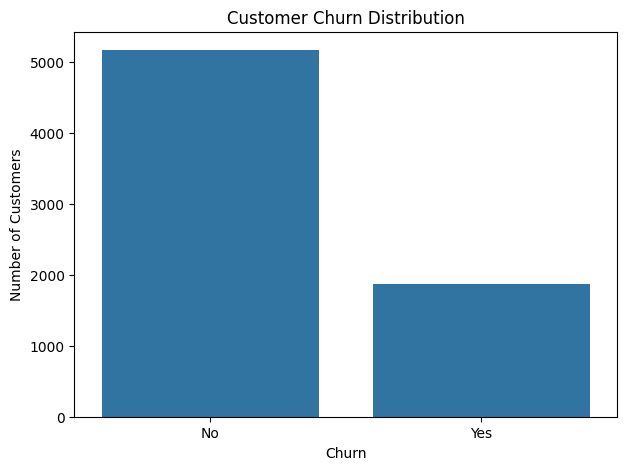

In [5]:
print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(
    df["Churn"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

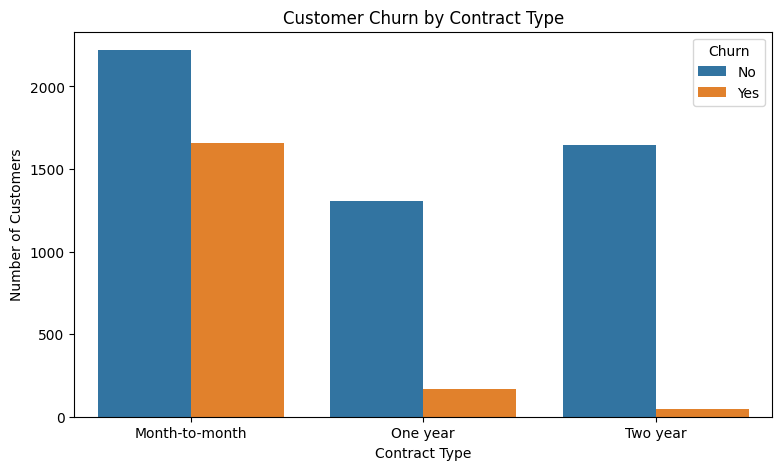

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

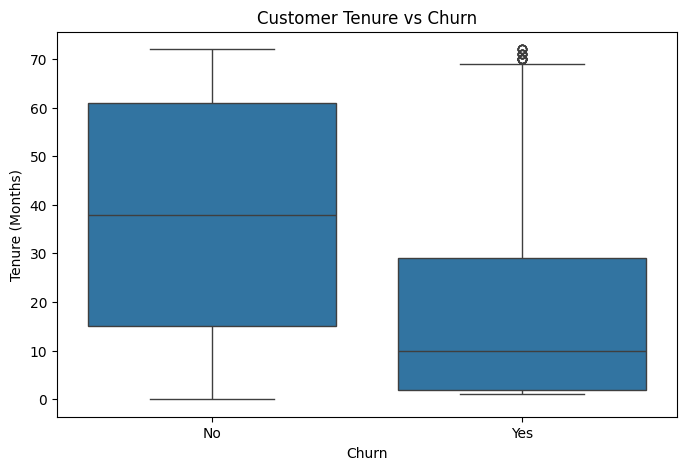

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [8]:
# Features
X = df.drop("Churn", axis=1)

# Target
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [9]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

# One-Hot Encoder compatibility
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", encoder, categorical_features)
    ]
)

print("\nPreprocessor created successfully!")

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessor created successfully!


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit only on training data
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Convert to float32 for TensorFlow
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (5634, 45)
Testing Features: (1409, 45)
Training Labels: (5634,)
Testing Labels: (1409,)


In [11]:
baseline_model = keras.Sequential([

    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")

])

baseline_model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
baseline_history = baseline_model.fit(

    X_train,
    y_train,

    validation_split=0.20,

    epochs=50,

    batch_size=32,

    verbose=1

)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7881 - loss: 0.4458 - val_accuracy: 0.7746 - val_loss: 0.4517
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8041 - loss: 0.4163 - val_accuracy: 0.7755 - val_loss: 0.4492
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8032 - loss: 0.4109 - val_accuracy: 0.7782 - val_loss: 0.4482
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8054 - loss: 0.4075 - val_accuracy: 0.7808 - val_loss: 0.4484
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8092 - loss: 0.4045 - val_accuracy: 0.7826 - val_loss: 0.4487
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8107 - loss: 0.4019 - val_accuracy: 0.7782 - val_loss: 0.4484
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8132 - loss: 0.3993 - val_accuracy: 0.7764 - val_loss: 0.4488
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8152 - loss: 0.3968 - val_accuracy: 0

In [13]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("BASELINE MODEL RESULTS")

print("Test Loss:", baseline_loss)

print("Test Accuracy:", baseline_accuracy * 100, "%")

BASELINE MODEL RESULTS
Test Loss: 0.5224997401237488
Test Accuracy: 76.22427344322205 %


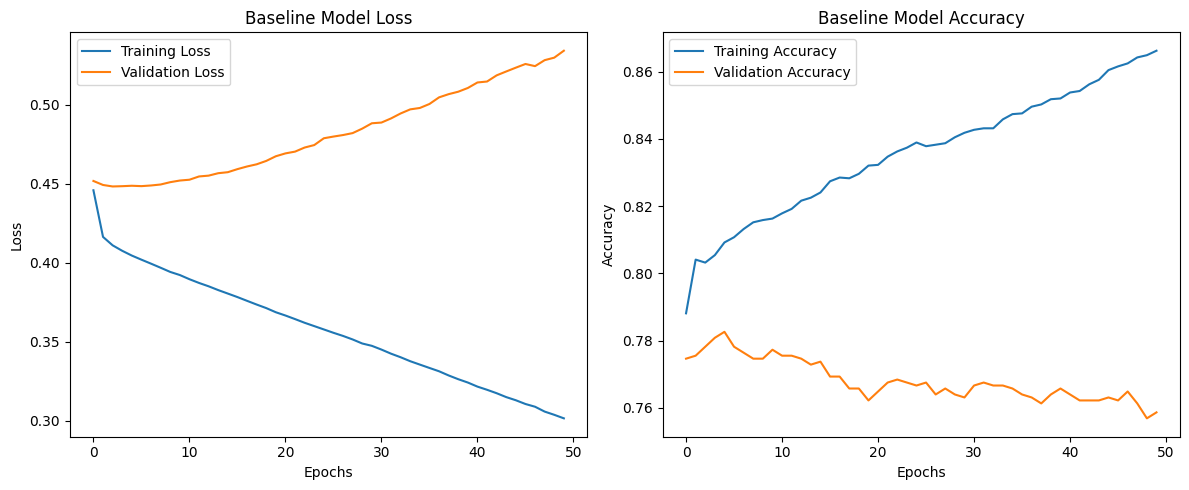

In [14]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(
    baseline_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
tuned_model = keras.Sequential([

    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.30),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.20),

    layers.Dense(1, activation="sigmoid")

])

tuned_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

tuned_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,593 (57.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [16]:
early_stopping = keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True

)

print("Early Stopping configured successfully!")

Early Stopping configured successfully!


In [17]:
tuned_history = tuned_model.fit(

    X_train,
    y_train,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[early_stopping],

    verbose=1

)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7167 - loss: 0.7422 - val_accuracy: 0.7862 - val_loss: 0.6127
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7770 - loss: 0.6113 - val_accuracy: 0.7968 - val_loss: 0.5770
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7870 - loss: 0.5816 - val_accuracy: 0.7862 - val_loss: 0.5758
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7910 - loss: 0.5630 - val_accuracy: 0.7844 - val_loss: 0.5762
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8021 - loss: 0.5434 - val_accuracy: 0.7844 - val_loss: 0.5728
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7959 - loss: 0.5389 - val_accuracy: 0.7826 - val_loss: 0.5628
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8008 - loss: 0.5264 - val_accuracy: 0.7862 - val_loss: 0.5604
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8063 - loss: 0.5169 - val_accu

In [18]:
tuned_loss, tuned_accuracy = tuned_model.evaluate(

    X_test,
    y_test,

    verbose=0

)

print("TUNED MODEL RESULTS")

print("Test Loss:", tuned_loss)

print("Test Accuracy:", tuned_accuracy * 100, "%")

TUNED MODEL RESULTS
Test Loss: 0.5163378715515137
Test Accuracy: 78.21149826049805 %


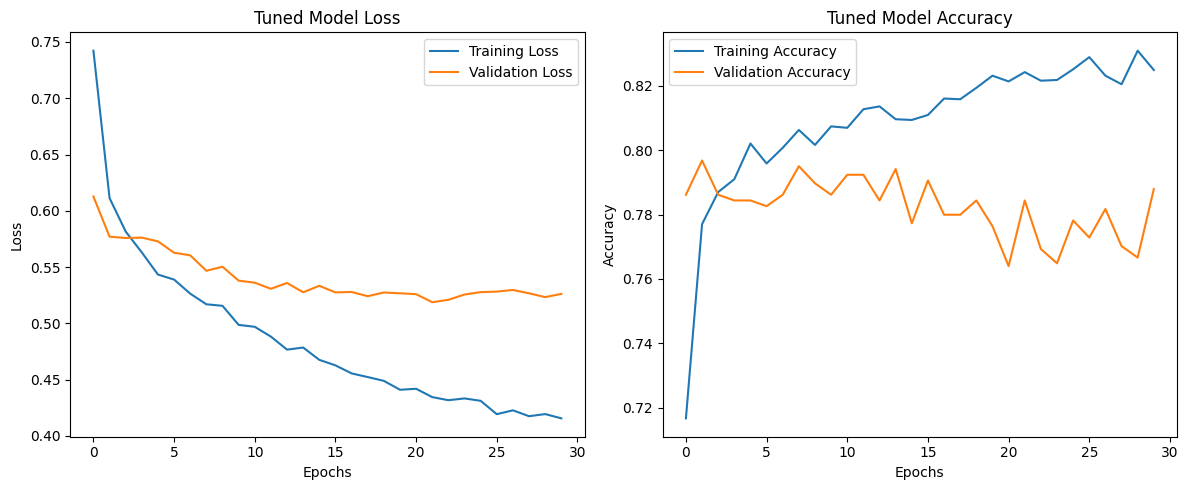

In [19]:
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    tuned_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    tuned_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Tuned Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    tuned_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    tuned_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Tuned Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

,Model,Test Accuracy,Test Loss
0,Baseline Model,76.224273,0.522500
1,Tuned Model,78.211498,0.516338


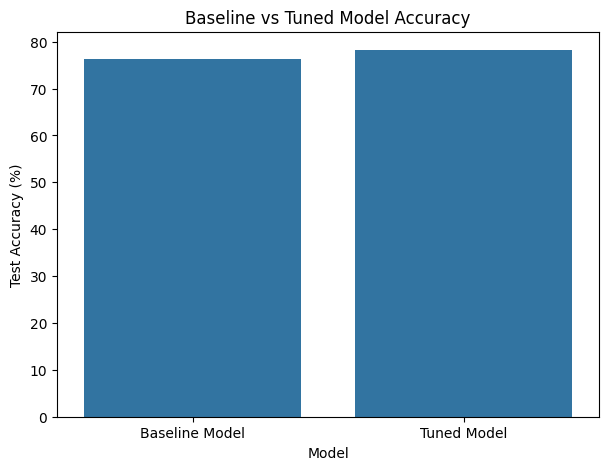

In [20]:
comparison = pd.DataFrame({

    "Model": ["Baseline Model", "Tuned Model"],

    "Test Accuracy": [
        baseline_accuracy * 100,
        tuned_accuracy * 100
    ],

    "Test Loss": [
        baseline_loss,
        tuned_loss
    ]

})

display(comparison)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test Accuracy"
)

plt.title("Baseline vs Tuned Model Accuracy")
plt.ylabel("Test Accuracy (%)")

plt.show()

In [21]:
if tuned_accuracy >= baseline_accuracy:

    best_model = tuned_model
    best_model_name = "Tuned Model"

else:

    best_model = baseline_model
    best_model_name = "Baseline Model"

print("Selected Best Model:", best_model_name)

Selected Best Model: Tuned Model


In [22]:
# Predictions
y_probability = best_model.predict(X_test)

y_prediction = (y_probability >= 0.5).astype(int).flatten()

# Calculate metrics
accuracy = accuracy_score(y_test, y_prediction)

precision = precision_score(
    y_test,
    y_prediction,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_prediction,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_prediction,
    zero_division=0
)

print("BEST MODEL EVALUATION")

print("----------------------------")

print("Accuracy:", round(accuracy, 4))

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
BEST MODEL EVALUATION
----------------------------
Accuracy: 0.7821
Precision: 0.6044
Recall: 0.5187
F1 Score: 0.5583


In [23]:
print(
    classification_report(
        y_test,
        y_prediction,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn       0.83      0.88      0.86      1035
       Churn       0.60      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409



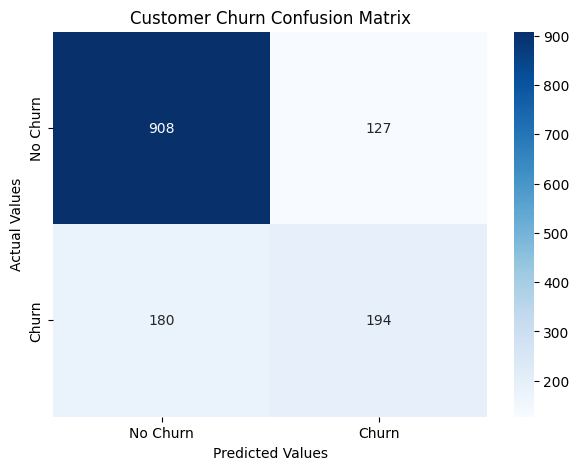

In [24]:
cm = confusion_matrix(y_test, y_prediction)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Customer Churn Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

In [25]:
# Save trained model
best_model.save("Customer_Churn_Model.keras")

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "Customer_Churn_Preprocessor.joblib"
)

print("Model saved successfully!")
print("Preprocessor saved successfully!")

Model saved successfully!
Preprocessor saved successfully!


In [26]:
def predict_customer_churn(customer_data):

    # Load saved model
    model = keras.models.load_model(
        "Customer_Churn_Model.keras"
    )

    # Load preprocessing pipeline
    preprocessing = joblib.load(
        "Customer_Churn_Preprocessor.joblib"
    )

    # Convert customer data into DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Preprocess customer data
    processed_data = preprocessing.transform(
        customer_df
    )

    processed_data = processed_data.astype("float32")

    # Predict churn probability
    probability = model.predict(
        processed_data,
        verbose=0
    )[0][0]

    # Classification
    prediction = "Yes" if probability >= 0.5 else "No"

    print("Customer Churn Prediction")
    print("-------------------------")

    print("Churn Probability:", round(float(probability) * 100, 2), "%")

    print("Predicted Churn:", prediction)

    if prediction == "Yes":
        print("This customer is likely to leave the company.")
    else:
        print("This customer is likely to stay with the company.")

    return prediction

In [27]:
new_customer = {

    "gender": "Female",

    "SeniorCitizen": 0,

    "Partner": "No",

    "Dependents": "No",

    "tenure": 2,

    "PhoneService": "Yes",

    "MultipleLines": "No",

    "InternetService": "Fiber optic",

    "OnlineSecurity": "No",

    "OnlineBackup": "No",

    "DeviceProtection": "No",

    "TechSupport": "No",

    "StreamingTV": "No",

    "StreamingMovies": "No",

    "Contract": "Month-to-month",

    "PaperlessBilling": "Yes",

    "PaymentMethod": "Electronic check",

    "MonthlyCharges": 70.70,

    "TotalCharges": 141.40

}

prediction = predict_customer_churn(new_customer)

Customer Churn Prediction
-------------------------
Churn Probability: 75.56 %
Predicted Churn: Yes
This customer is likely to leave the company.


In [28]:
files.download("Customer_Churn_Model.keras")

files.download("Customer_Churn_Preprocessor.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>